# Лабораторная работа 1

Книга: Ф. М. Достоевский, «Преступление и наказание». Текст взят с Lib.ru

In [14]:
import re, math, random
from collections import Counter, defaultdict
from pathlib import Path

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

for path, package in [('tokenizers/punkt', 'punkt'), ('tokenizers/punkt_tab', 'punkt_tab')]:
    try:
        nltk.data.find(path)
    except LookupError:
        nltk.download(package, quiet=True)
random.seed(42)

## 1. Токенизация и статистика

In [16]:
text = Path('data/prestuplenie_i_nakazanie.txt').read_text()
print('Слов при грубом подсчёте:', len(text.split()))

split_tokens = text.split()
nltk_tokens = nltk.word_tokenize(text, language='russian')
print('split():', split_tokens[:20])
print('NLTK:', nltk_tokens[:20])

Слов при грубом подсчёте: 191681
split(): ['Часть', 'первая', 'I', 'В', 'начале', 'июля,', 'в', 'чрезвычайно', 'жаркое', 'время,', 'под', 'вечер,', 'один', 'молодой', 'человек', 'вышел', 'из', 'своей', 'каморки,', 'которую']
NLTK: ['Часть', 'первая', 'I', 'В', 'начале', 'июля', ',', 'в', 'чрезвычайно', 'жаркое', 'время', ',', 'под', 'вечер', ',', 'один', 'молодой', 'человек', 'вышел', 'из']


`split()` оставляет пунктуацию со словами. NLTK выделяет её в отдельные токены и лучше разбирает тире и кавычки

N = 180499
V = 27522


,слово,частота
0,и,9175
1,в,4313
2,не,3935
3,что,3355
4,он,2932
5,на,2549
6,я,2449
7,с,2188
8,а,1838
9,как,1726


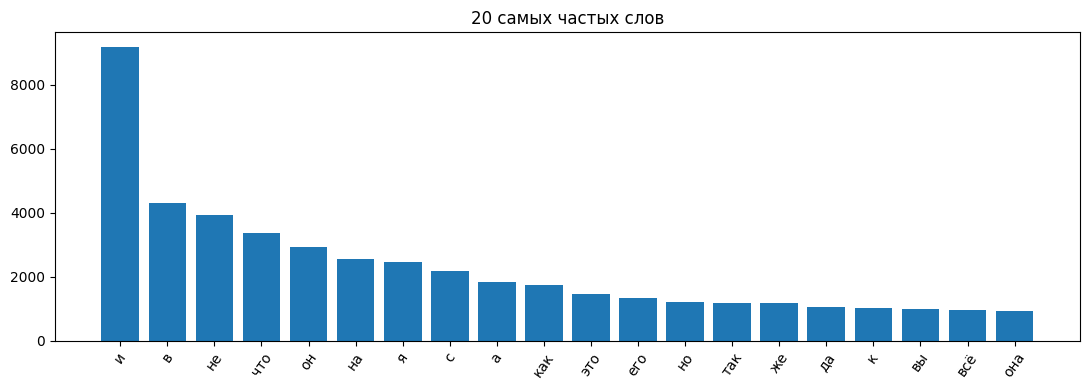

In [17]:
tokens = [x.lower() for x in nltk_tokens if re.fullmatch(r'[а-яё]+', x.lower())]
freq = Counter(tokens)
N, V = len(tokens), len(freq)
print('N =', N)
print('V =', V)

top20 = pd.DataFrame(freq.most_common(20), columns=['слово', 'частота'])
display(top20)

plt.figure(figsize=(11, 4))
plt.bar(top20['слово'], top20['частота'])
plt.xticks(rotation=55)
plt.title('20 самых частых слов')
plt.tight_layout()
plt.show()

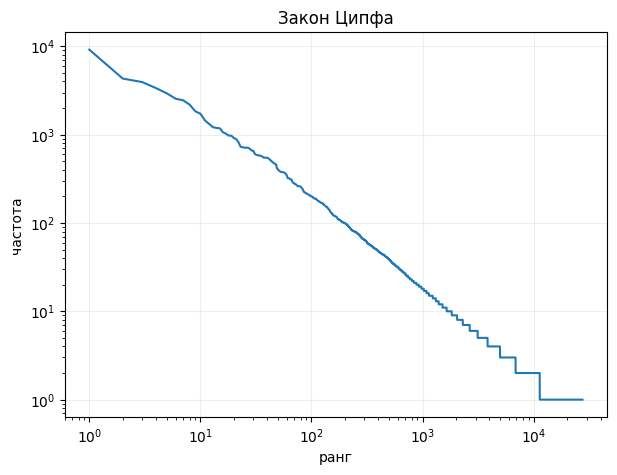

In [18]:
counts = np.array(sorted(freq.values(), reverse=True))
ranks = np.arange(1, len(counts) + 1)
plt.figure(figsize=(7, 5))
plt.loglog(ranks, counts)
plt.xlabel('ранг')
plt.ylabel('частота')
plt.title('Закон Ципфа')
plt.grid(alpha=.2)
plt.show()

В логарифмических координатах получилась почти прямая, частота слова примерно обратно пропорциональна его рангу. В языке мало слов с высокой частотой и много слов с низкой частотой, так как различные предлоги и другие служебные части речи встречаются чаще, чем узконаправленные слова

## 2. Редакционное расстояние

In [20]:
def edit_distance(s1, s2):
    dp = np.zeros((len(s1) + 1, len(s2) + 1), dtype=int)
    dp[:, 0] = np.arange(len(s1) + 1)
    dp[0, :] = np.arange(len(s2) + 1)
    for i in range(1, len(s1) + 1):
        for j in range(1, len(s2) + 1):
            if s1[i-1] == s2[j-1]:
                cost = 0
            else:
                cost = 1
            dp[i, j] = min(dp[i-1, j] + 1, dp[i, j-1] + 1, dp[i-1, j-1] + cost)
    return dp[-1, -1], dp

In [21]:
pairs = [
    ('кот', 'кот'), ('кот', 'код'), ('мама', 'рама'), ('intention', 'execution'), ('дом', 'дым'), ('стол', 'стул'), ('книга', 'книги'), ('машина', 'малина'), ('мир', 'рим'), ('алгоритм', 'алгоритмм')
]

for a, b in pairs:
    d, matrix = edit_distance(a, b)
    print(f'{a} -> {b}: {d}')
    display(pd.DataFrame(matrix, index=['Ø'] + list(a), columns=['Ø'] + list(b)))

кот -> кот: 0


,Ø,к,о,т
Ø,0,1,2,3
к,1,0,1,2
о,2,1,0,1
т,3,2,1,0


кот -> код: 1


,Ø,к,о,д
Ø,0,1,2,3
к,1,0,1,2
о,2,1,0,1
т,3,2,1,1


мама -> рама: 1


,Ø,р,а,м,а
Ø,0,1,2,3,4
м,1,1,2,2,3
а,2,2,1,2,2
м,3,3,2,1,2
а,4,4,3,2,1


... (10 outputs left out)

мир -> рим: 2


,Ø,р,и,м
Ø,0,1,2,3
м,1,1,2,2
и,2,2,1,2
р,3,2,2,2


алгоритм -> алгоритмм: 1


,Ø,а,л,г,о,р,и,т,м,м
Ø,0,1,2,3,4,5,6,7,8,9
а,1,0,1,2,3,4,5,6,7,8
л,2,1,0,1,2,3,4,5,6,7
г,3,2,1,0,1,2,3,4,5,6
о,4,3,2,1,0,1,2,3,4,5
р,5,4,3,2,1,0,1,2,3,4
и,6,5,4,3,2,1,0,1,2,3
т,7,6,5,4,3,2,1,0,1,2
м,8,7,6,5,4,3,2,1,0,1


In [22]:
typo = 'алгоритмм'
candidates = []
for word in freq:
    if abs(len(word) - len(typo)) <= 2:
        candidates.append((word, edit_distance(typo, word)[0], freq[word]))

pd.DataFrame(sorted(candidates, key=lambda x: (x[1], -x[2]))[:5],
             columns=['слово', 'расстояние', 'частота'])

,слово,расстояние,частота
0,авторитет,4,1
1,говорит,5,80
2,говорить,5,76
3,говорите,5,39
4,отворить,5,5


Метод находит похожие написания, но не понимает контекст. Ещё правильное слово должно присутствовать в словаре корпуса. Судя по выводу, такого слова у Достоевского нет

In [23]:
typo = 'преступленне'
candidates = []
for word in freq:
    if abs(len(word) - len(typo)) <= 2:
        candidates.append((word, edit_distance(typo, word)[0], freq[word]))

pd.DataFrame(sorted(candidates, key=lambda x: (x[1], -x[2]))[:5],
             columns=['слово', 'расстояние', 'частота'])

,слово,расстояние,частота
0,преступление,1,62
1,преступления,2,77
2,преступлении,2,18
3,преступлению,2,9
4,преступлений,2,6


Теория подтвердилась, слово преступление и его производные корректно нашлось

## 3. N-грамм модели

In [24]:
cut = int(len(tokens) * .8)
train, test = tokens[:cut], tokens[cut:]
vocab = set(train)
V_train = len(vocab)
print(len(train), len(test), V_train)

unigrams = Counter(train)
bigrams = Counter(zip(train[:-1], train[1:]))
rows = []
for (a, b), c in bigrams.most_common(15):
    rows.append((a, b, c, c / unigrams[a]))
pd.DataFrame(rows, columns=['w1', 'w2', 'count', 'P(w2|w1)'])

144399 36100 22249


,w1,w2,count,P(w2|w1)
0,и,не,321,0.043549
1,да,и,191,0.197723
2,как,бы,184,0.128045
3,как,будто,177,0.123173
4,что,он,173,0.061676
5,что,я,173,0.061676
6,может,быть,172,0.547771
7,и,в,159,0.021571
8,и,с,152,0.020621
9,потому,что,141,0.512727


In [25]:
next_words = defaultdict(Counter)
for a, b in zip(train[:-1], train[1:]):
    next_words[a][b] += 1

starts = [w for w, _ in unigrams.most_common(100) if w in next_words]
for _ in range(3):
    sent = [random.choice(starts)]
    for i in range(11):
        variants = next_words.get(sent[-1])
        if not variants:
            sent.append(random.choice(starts))
        else:
            sent.append(random.choices(list(variants), weights=list(variants.values()))[0])
    print(' '.join(sent).capitalize() + '.')

Будто и будьте уверены что же убедишься что слова не знал что.
Для чего и минуты настасья и вошел завитой у перил облокотился на.
Бы не взбунтуется и вперед прибавим только не видал и что чувства.


Предложения местами похожи на исходный стиль, но длинных связей биграмма не удерживает, поэтому смысл быстро теряется

In [10]:
def bigram_pp(train_part, test_part):
    uni = Counter(train_part)
    bi = Counter(zip(train_part[:-1], train_part[1:]))
    v = len(uni)
    logs = []
    for a, b in zip(test_part[:-1], test_part[1:]):
        logs.append(math.log((bi[a, b] + 1) / (uni[a] + v)))
    return math.exp(-sum(logs) / len(logs))

def trigram_pp(train_part, test_part):
    ctx = Counter(zip(train_part[:-1], train_part[1:]))
    tri = Counter(zip(train_part[:-2], train_part[1:-1], train_part[2:]))
    v = len(set(train_part))
    logs = []
    for a, b, c in zip(test_part[:-2], test_part[1:-1], test_part[2:]):
        logs.append(math.log((tri[a, b, c] + 1) / (ctx[a, b] + v)))
    return math.exp(-sum(logs) / len(logs))

pp2 = bigram_pp(train, test)
pp3 = trigram_pp(train, test)
print('Биграмма:', round(pp2, 2))
print('Триграмма:', round(pp3, 2))

Биграмма: 11927.46
Триграмма: 20658.24


Триграмма использует больше контекста, но при простом add-1 часто проигрывает из-за большого числа редких и невиденных сочетаний

В формулах добавляются + 1 в числителе и + v в знаменателе. Это сглаживание Лапласа, без него неизвестная биграмма получила бы нулевую вероятность и обнулила вероятность всего текста

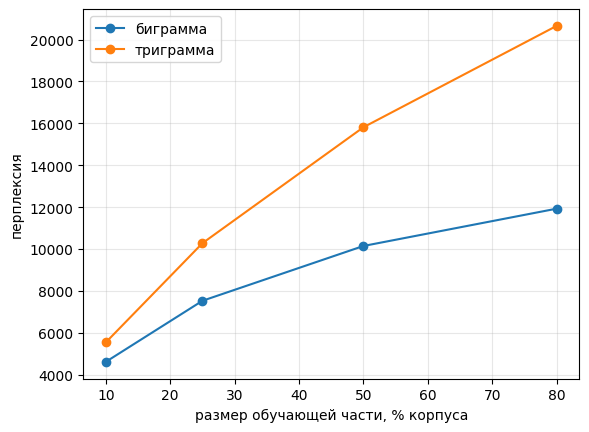

In [11]:
parts = [.10, .25, .50, .80]
pp_bi, pp_tri = [], []
for p in parts:
    tr = tokens[:int(len(tokens) * p)]
    pp_bi.append(bigram_pp(tr, test))
    pp_tri.append(trigram_pp(tr, test))

plt.plot([10, 25, 50, 80], pp_bi, 'o-', label='биграмма')
plt.plot([10, 25, 50, 80], pp_tri, 'o-', label='триграмма')
plt.xlabel('размер обучающей части, % корпуса')
plt.ylabel('перплексия')
plt.legend()
plt.grid(alpha=.3)
plt.show()

Здесь перплексия растёт вместе с размером обучающей выборки. Причина в том, что одновременно увеличивается словарь V, а сглаживание add-1 распределяет вероятность между стремительно растущим числом слов. Особенно это заметно для редких триграмм. Это результат несовершенности сглаживания Лапласа

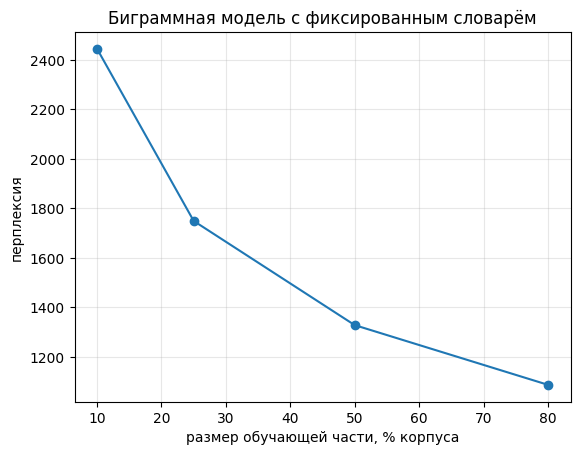

[2443.842529868218, 1749.0279194979864, 1328.5279083685903, 1087.5354447457844]

In [26]:
max_train = tokens[:cut]
counts = Counter(max_train)

fixed_vocab = {word for word, count in counts.items() if count >= 2}
fixed_vocab.add('<UNK>')
V_fixed = len(fixed_vocab)

def replace_unknown(words):
    return [word if word in fixed_vocab else '<UNK>' for word in words]

fixed_test = replace_unknown(test)

def bigram_pp_fixed(train_part, test_part):
    train_part = replace_unknown(train_part)

    unigrams = Counter(train_part)
    bigrams = Counter(zip(train_part[:-1], train_part[1:]))

    log_prob = 0
    for w1, w2 in zip(test_part[:-1], test_part[1:]):
        probability = (bigrams[w1, w2] + 1) / (unigrams[w1] + V_fixed)
        log_prob += math.log(probability)

    return math.exp(-log_prob / (len(test_part) - 1))

sizes = [10, 25, 50, 80]
values = []

for size in sizes:
    train_part = tokens[:int(len(tokens) * size / 100)]
    values.append(bigram_pp_fixed(train_part, fixed_test))

plt.plot(sizes, values, 'o-')
plt.xlabel('размер обучающей части, % корпуса')
plt.ylabel('перплексия')
plt.title('Биграммная модель с фиксированным словарём')
plt.grid(alpha=.3)
plt.show()

values

После фиксации словаря поведение стало более стабильным и правильным. В коде размер больше не изменяется вместе с обучающей выборкой, а неизвестные и редкие слова заменяются токеном UNK. Это дало рост стабильности при росте обучающей выборки